# Projet 5 - Antoine MOREL - Etienne SEILLE - Delvin TRAN

**Question** : peut-on détecter des attaques inconnues sans exemples de ces attaques à l'entraînement ?

**Problématique** : Peut-on construire une défense réseau efficace en se basant uniquement sur un comportement normal ?


**Approche** : apprendre uniquement le trafic normal, puis signaler ce qui s'en écarte.

**Hypothèses**:
- **H1** : les détecteurs ont des compromis différents entre détection et faux positifs.
- **H2** : contaminer l'entraînement avec des attaques dégrade la détection.
- **H3** : les détecteurs d'anomalies sont moins précis qu'un modèle supervisé, mais meilleurs sur certaines attaques inconnues.

# Phase 1 - Compréhension du dataset et EDA ciblée

## 1.1 Configuration et parametres

In [1]:
import os
import time
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, PrecisionRecallDisplay, RocCurveDisplay,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

#Paramètres
RANDOM_STATE = 42
DATA_DIR = os.environ.get("UNSW_DATA_DIR", "../data/raw")
TRAIN_FILE = "UNSW_NB15_training-set.csv"
TEST_FILE = "UNSW_NB15_testing-set.csv"
OUT_DIR = "results"                    # tableaux et figures pour le rapport

VAL_SIZE = 0.2                         # part du train gardée pour la validation
N_FIT = 20_000                         # flux normaux d'entraînement (coût de LOF / OC-SVM)
TARGET_FPR = 0.05                      # budget de fausses alertes pour fixer le seuil
FPR_LEVELS = [0.01, 0.02, 0.05, 0.10]  # budgets testés
CONTAMINATION_LEVELS = [0.0, 0.01, 0.02, 0.05, 0.10]  # part d'attaques dans l'entraînement (Exp. 2)
N_SEEDS = 3                            # tirages par niveau de contamination (Exp. 2)
UNKNOWN_FAMILIES = ["Reconnaissance", "Backdoor", "Shellcode", "Worms"]  # familles « inconnues » (Exp. 3)
CLIP_QUANTILE = 0.99                   # écrêtage des valeurs extrêmes

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)

def save_fig(fig, name):
    fig.savefig(os.path.join(OUT_DIR, f"{name}.png"), bbox_inches="tight")

def save_table(df, name):
    df.to_csv(os.path.join(OUT_DIR, f"{name}.csv"))

pd.Series({"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
       "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}, name="version").to_frame()


,version
Python,3.14.8
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
scipy,1.18.1
matplotlib,3.11.2
seaborn,0.13.2


## 1.2 Chargement

UNSW-NB15 : un flux réseau par ligne, 42 variables, `label` (0 normal / 1 attaque) et `attack_cat` (famille).

In [2]:
train_df = pd.read_csv(os.path.join(DATA_DIR, TRAIN_FILE))
test_df = pd.read_csv(os.path.join(DATA_DIR, TEST_FILE))

for df in (train_df, test_df):
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip()

FEATURES = [c for c in train_df.columns if c not in ("id", "attack_cat", "label")]
CAT_COLS = ["proto", "service", "state"]

print("Valeurs manquantes :", int(train_df.isna().sum().sum()), "/", int(test_df.isna().sum().sum()))

Valeurs manquantes : 0 / 0


## 1.3 EDA ciblée

On regarde si les familles inconnues ont assez de flux de test et on retire les doublons du **train**


Part de flux normaux dupliqués dans le train : 7.3%


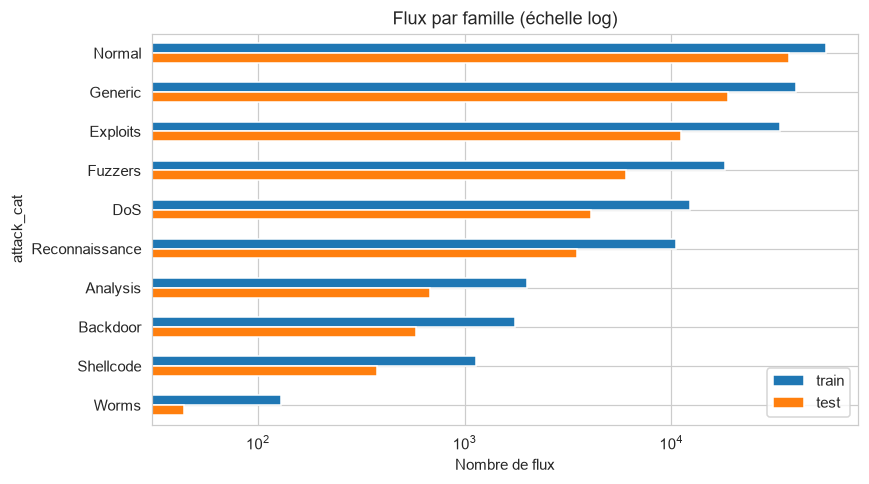

,train,test,inconnue (Exp. 3)
attack_cat,,,
Normal,56000,37000,False
Generic,40000,18871,False
Exploits,33393,11132,False
Fuzzers,18184,6062,False
DoS,12264,4089,False
Reconnaissance,10491,3496,True
Analysis,2000,677,False
Backdoor,1746,583,True
Shellcode,1133,378,True


In [3]:
fam = pd.DataFrame({
    "train": train_df["attack_cat"].value_counts(),
    "test": test_df["attack_cat"].value_counts(),
}).fillna(0).astype(int).sort_values("train", ascending=False) #on compte les lignes et 0 si une famille est absente
fam["inconnue (Exp. 3)"] = fam.index.isin(UNKNOWN_FAMILIES) #True si la famille est notée comme inconnues précédemment

dup_normal = train_df[train_df["label"] == 0].duplicated(subset=FEATURES).mean()
print(f"Part de flux normaux dupliqués dans le train : {dup_normal:.1%}")

fig, ax = plt.subplots(figsize=(8, 4.5))
fam[["train", "test"]].plot(kind="barh", logx=True, ax=ax)
ax.invert_yaxis()
ax.set_title("Flux par famille (échelle log)")
ax.set_xlabel("Nombre de flux")
plt.tight_layout(); save_fig(fig, "eda_familles"); plt.show()
fam

Sur le **train** on compare les attaques et normales pour différencier leurs comportement, si décalage -> on peut utiliser un détecteur sinon difficile avec un détecteur

Log appliqué pour visualiser correctement

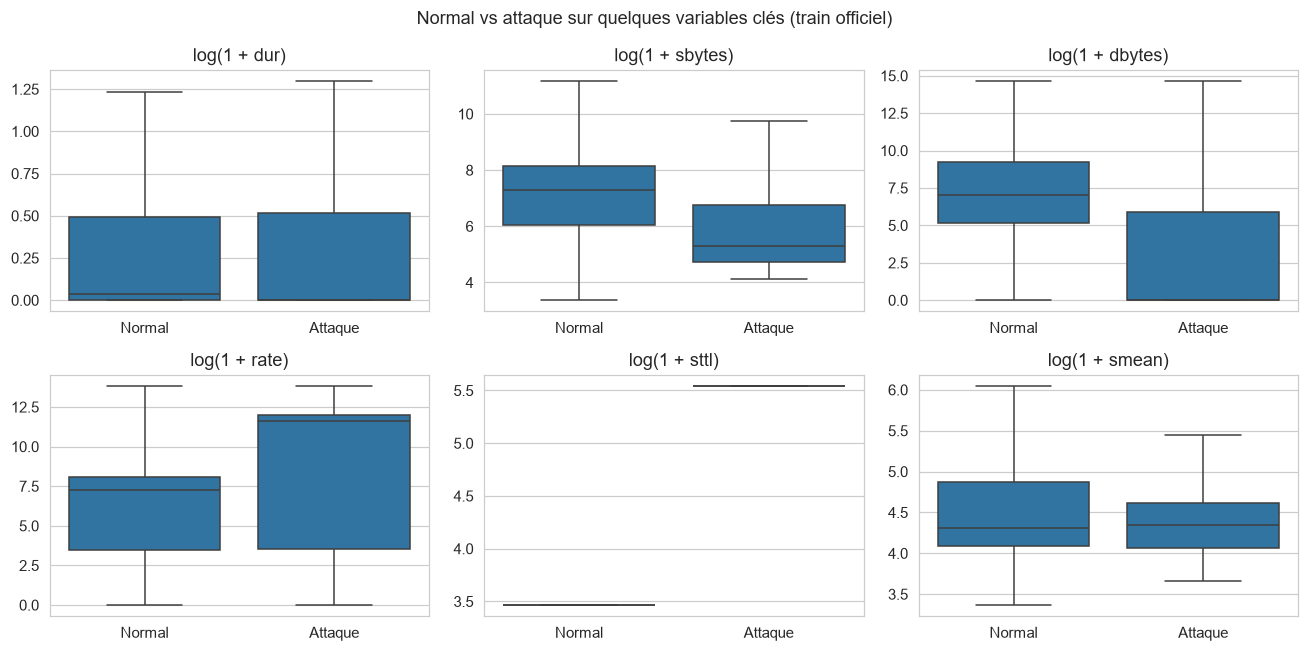

In [4]:
KEY_VARS = [c for c in ["dur", "sbytes", "dbytes", "rate", "sttl", "smean"] if c in FEATURES]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), KEY_VARS):
    sns.boxplot(data=train_df.assign(classe=train_df["label"].map({0: "Normal", 1: "Attaque"})),
                x="classe", y=np.log1p(train_df[col]), ax=ax, showfliers=False)
    ax.set_title(f"log(1 + {col})"); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Normal vs attaque sur quelques variables clés (train officiel)")
plt.tight_layout(); save_fig(fig, "eda_variables_cles"); plt.show()

## 1.4 Conclusions

- Trafic normal abondant -> on apprend sur un échantillon de `N_FIT` flux.
- Familles rares (Worms, Shellcode) -> taux de détection peu fiables.
- Doublons -> retirés de l'entraînement, gardés en validation et test.
- Distributions très asymétriques -> transformation log.

# Phase 2 - Préparation, pipeline et baseline

## 2.1 Découpage
80% pour l'entrainement et 20% pour la validation en gardant la même proportions de chaque famille

Jeu d'entraînement 20000 de flux normaux


In [5]:
train_part, val_df = train_test_split(
    train_df, test_size=VAL_SIZE, stratify=train_df["attack_cat"], random_state=RANDOM_STATE)

normal_pool = train_part[train_part["label"] == 0].drop_duplicates(subset=FEATURES)
attack_pool = train_part[train_part["label"] == 1]

X_val, y_val = val_df[FEATURES], val_df["label"].to_numpy()
X_test, y_test = test_df[FEATURES], test_df["label"].to_numpy()
val_normal = y_val == 0
X_val_normal = X_val[val_normal]

N_FIT = min(N_FIT, len(normal_pool))
X_fit = normal_pool.sample(n=N_FIT, random_state=RANDOM_STATE)[FEATURES]

num_cols = [c for c in FEATURES if c not in CAT_COLS]
CONT_COLS = [c for c in num_cols if normal_pool[c].nunique() > 50]
DISC_COLS = [c for c in num_cols if c not in CONT_COLS]

splits = pd.DataFrame({
    "flux": [len(normal_pool), len(attack_pool), N_FIT, len(val_df), len(test_df)],
    "dont attaques": [0, len(attack_pool), 0, int(y_val.sum()), int(y_test.sum())],
}, index=["Pool normal (sans doublons)", "Pool attaques", "Entraînement détecteurs (N_FIT)",
          "Validation", "Test officiel"])
save_table(splits, "decoupage")
splits

,flux,dont attaques
Pool normal (sans doublons),41836,0
Pool attaques,95472,95472
Entraînement détecteurs (N_FIT),20000,0
Validation,35069,23869
Test officiel,82332,45332


**Contrôles de non-fuite**

Contrôle à chaque exécution l'absence de fuite de données

In [6]:
assert (train_df.loc[X_fit.index, "label"] == 0).all(), "Une attaque s'est glissée dans l'entraînement"
assert X_fit.index.isin(train_part.index).all(), "L'entraînement doit venir des 80 % du train officiel"
assert not X_fit.index.isin(val_df.index).any(), "Recouvrement entre entraînement et validation"
assert not X_fit.duplicated().any(), "Il reste des doublons dans l'entraînement"
print("Contrôles réussis : entraînement 100 % normal, sans doublon, disjoint de la validation.")
print(f"Validation : {int((y_val == 0).sum())} flux normaux, {int(y_val.sum())} attaques")
print(f"Test officiel (fichier séparé) : {int((y_test == 0).sum())} flux normaux, {int(y_test.sum())} attaques")

Contrôles réussis : entraînement 100 % normal, sans doublon, disjoint de la validation.
Validation : 11200 flux normaux, 23869 attaques
Test officiel (fichier séparé) : 37000 flux normaux, 45332 attaques


## 2.2 Pipeline de prétraitement

Appris sur l'entraînement seulement, puis appliqué tel quel à la validation et au test.

| Variables | Traitement |
|---|---|
| Continues (> 50 valeurs distinctes) | Écrêtage au 99e percentile → `log1p` → standardisation |
| Discrètes | Standardisation |
| Catégorielles | One-hot des 5 modalités les plus fréquentes + « rare » |

In [7]:
class QuantileClipper(BaseEstimator, TransformerMixin): #plafonne les valeurs extremes
    def __init__(self, upper_quantile=0.99):
        self.upper_quantile = upper_quantile
    def fit(self, X, y=None):
        self.upper_ = np.quantile(np.asarray(X, dtype=float), self.upper_quantile, axis=0)
        return self
    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.upper_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def log1p_pos(X): #Compresse les grandes valeurs
    return np.log1p(np.clip(X, 0, None))


def build_preprocessor(cont_cols, disc_cols, cat_cols): # en fonction du groupe de colonnes, on l'envoie dans un traitement adapté
    cont_pipe = Pipeline([
        ("clip", QuantileClipper(CLIP_QUANTILE)),
        ("log", FunctionTransformer(log1p_pos, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("cont", cont_pipe, cont_cols),
        ("disc", StandardScaler(), disc_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=6), cat_cols),
    ], sparse_threshold=0)


def make_pipeline(model, cols=None):
    cont, disc, cat = cols or (CONT_COLS, DISC_COLS, CAT_COLS)
    return Pipeline([("prep", build_preprocessor(cont, disc, cat)), ("model", model)])

**Vérification** : moyenne 0 et écart-type 1 sur l'entraînement uniquement (pas de fuite).

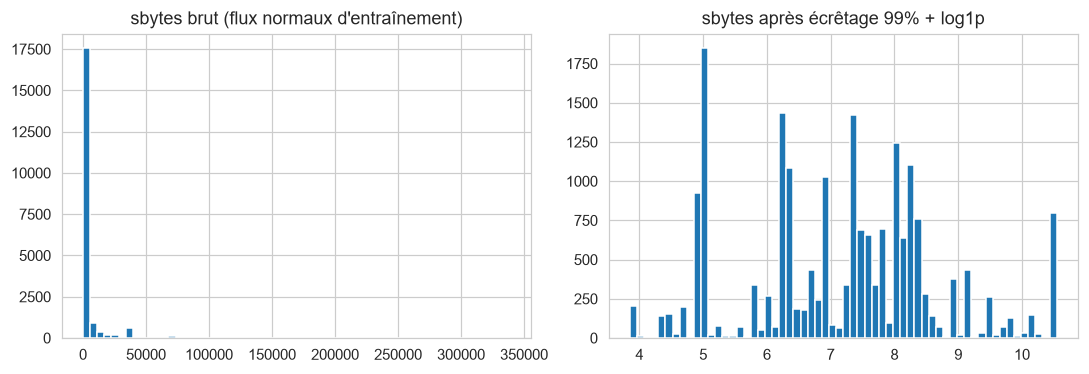

Dimension après prétraitement : 57 colonnes (22 continues, 17 discrètes, 18 one-hot)
Moyenne et écart-type des variables continues transformées :


,moyenne,écart-type
Entraînement (X_fit),-0.000,1.000
Validation,-0.348,1.271
Test,-0.292,1.262


In [8]:
col = "sbytes"
clip = QuantileClipper(CLIP_QUANTILE).fit(X_fit[[col]])
after = log1p_pos(clip.transform(X_fit[[col]])).ravel()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(X_fit[col], bins=60)
axes[0].set_title(f"{col} brut (flux normaux d'entraînement)")
axes[1].hist(after, bins=60)
axes[1].set_title(f"{col} après écrêtage {CLIP_QUANTILE:.0%} + log1p")
plt.tight_layout(); save_fig(fig, "phase2_effet_pretraitement"); plt.show()

prep = build_preprocessor(CONT_COLS, DISC_COLS, CAT_COLS).fit(X_fit)
names = prep.get_feature_names_out()
n_cont = len(CONT_COLS)
check = pd.DataFrame({
    jeu: {"moyenne": prep.transform(X)[:, :n_cont].mean(), "écart-type": prep.transform(X)[:, :n_cont].std()}
    for jeu, X in [("Entraînement (X_fit)", X_fit), ("Validation", X_val), ("Test", X_test)]
}).T
print(f"Dimension après prétraitement : {len(names)} colonnes "
      f"({len(CONT_COLS)} continues, {len(DISC_COLS)} discrètes, {len(names) - len(CONT_COLS) - len(DISC_COLS)} one-hot)")
print("Moyenne et écart-type des variables continues transformées :")
check.style.format("{:.3f}")

## 2.3 Baseline et outils communs

**Baseline z-score** : score = écart moyen au trafic normal, en écarts-types. Modèle minimal à battre.

**Seuil** : 95e percentile des scores des flux normaux de validation (FPR visé 5 %). Aucune attaque utilisée.

**Métriques** : précision, rappel, F1, Macro-F1, FPR, ROC-AUC, PR-AUC (pas d'accuracy seule).

In [9]:
class ZScoreBaseline(BaseEstimator):
    #Baseline : écart absolu moyen (en écarts-types) au trafic normal d'entraînement.
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.mu_, self.sd_ = X.mean(axis=0), X.std(axis=0)
        self.sd_[self.sd_ == 0] = 1.0   # évite une division par zéro pour une variable constante
        return self

    def score_samples(self, X):
        # Convention scikit-learn : score élevé = normal. On renvoie donc l'opposé de l'écart moyen.
        X = np.asarray(X, dtype=float)
        return -np.abs((X - self.mu_) / self.sd_).mean(axis=1)


def anomaly_score(pipe, X):
    #Plus le score est élevé, plus le flux est anormal.
    return -pipe.score_samples(X)


def threshold_from_normals(scores_normal, target_fpr=TARGET_FPR):
    #Seuil tel qu'une part target_fpr des flux normaux le dépasse.
    #Exemple : target_fpr = 5 % -> 95e percentile des scores normaux de validation.
    #Aucune attaque n'est utilisée (cohérent avec le scénario étudié).
    return np.quantile(scores_normal, 1 - target_fpr)


def detection_metrics(y, scores, thr):
    pred = (scores >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "Précision": precision_score(y, pred, zero_division=0),
        "Rappel": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Macro-F1": f1_score(y, pred, average="macro", zero_division=0),
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        "ROC-AUC": roc_auc_score(y, scores),
        "PR-AUC": average_precision_score(y, scores),
        "FP": int(fp), "FN": int(fn),
    }


PCT_COLS = ["Précision", "Rappel", "F1", "Macro-F1", "FPR", "ROC-AUC", "PR-AUC"]

def fmt(df):
    cols = [c for c in PCT_COLS if c in df.columns]
    return df.style.format({c: "{:.1%}" for c in cols}, precision=2)

## 2.4 Évaluation de la baseline

In [10]:
baseline = Pipeline([
    ("prep", build_preprocessor(CONT_COLS, DISC_COLS, CAT_COLS)),
    ("model", ZScoreBaseline()),
])
t0 = time.perf_counter()
baseline.fit(X_fit)
t_fit = time.perf_counter() - t0

s_val_bl, s_test_bl = anomaly_score(baseline, X_val), anomaly_score(baseline, X_test)
thr_bl = threshold_from_normals(s_val_bl[val_normal])

bl_results = pd.DataFrame({
    "Validation": detection_metrics(y_val, s_val_bl, thr_bl),
    "Test officiel": detection_metrics(y_test, s_test_bl, thr_bl),
}).T
save_table(bl_results, "phase2_baseline")
print(f"Baseline entraînée en {t_fit:.2f} s sur {len(X_fit)} flux normaux | seuil = {thr_bl:.3f}")
print(f"Proportion d'attaques (PR-AUC d'un modèle aléatoire) : validation {y_val.mean():.1%}, test {y_test.mean():.1%}")
fmt(bl_results)

Baseline entraînée en 0.05 s sur 20000 flux normaux | seuil = 1.356
Proportion d'attaques (PR-AUC d'un modèle aléatoire) : validation 68.1%, test 55.1%


,Précision,Rappel,F1,Macro-F1,FPR,ROC-AUC,PR-AUC,FP,FN
Validation,96.0%,55.7%,70.5%,68.1%,5.0%,86.1%,92.9%,561.00,10571.00
Test officiel,93.9%,43.1%,59.1%,65.8%,3.5%,80.5%,86.4%,1277.00,25805.00


**Distribution des scores, courbes ROC / PR, rappel selon le budget de FPR**

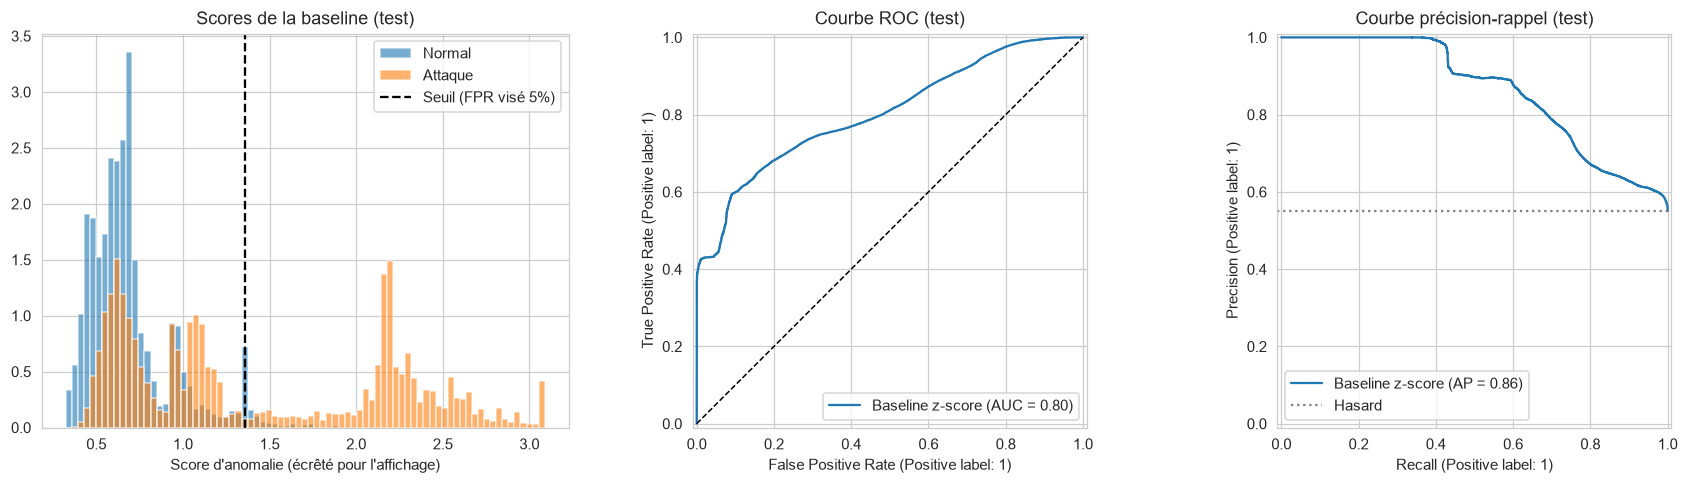

,FPR obtenu (test),Rappel (test),Précision (test)
FPR visé (validation),,,
1%,0.9%,42.0%,98.3%
2%,2.2%,43.0%,96.0%
5%,3.5%,43.1%,93.9%
10%,11.3%,60.9%,86.8%


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
lo, hi = np.quantile(s_test_bl, [0.001, 0.995])
bins = np.linspace(lo, hi, 80)
sc = np.clip(s_test_bl, lo, hi)
axes[0].hist(sc[y_test == 0], bins=bins, alpha=0.6, density=True, label="Normal")
axes[0].hist(sc[y_test == 1], bins=bins, alpha=0.6, density=True, label="Attaque")
axes[0].axvline(np.clip(thr_bl, lo, hi), color="black", ls="--", label=f"Seuil (FPR visé {TARGET_FPR:.0%})")
axes[0].set_title("Scores de la baseline (test)"); axes[0].set_xlabel("Score d'anomalie (écrêté pour l'affichage)")
axes[0].legend()
RocCurveDisplay.from_predictions(y_test, s_test_bl, name="Baseline z-score", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("Courbe ROC (test)")
PrecisionRecallDisplay.from_predictions(y_test, s_test_bl, name="Baseline z-score", ax=axes[2])
axes[2].axhline(y_test.mean(), color="grey", ls=":", label="Hasard"); axes[2].legend()
axes[2].set_title("Courbe précision-rappel (test)")
plt.tight_layout(); save_fig(fig, "phase2_baseline_scores"); plt.show()

rows = []
for f in FPR_LEVELS:
    m = detection_metrics(y_test, s_test_bl, threshold_from_normals(s_val_bl[val_normal], f))
    rows.append({"FPR visé (validation)": f"{f:.0%}", "FPR obtenu (test)": m["FPR"],
                 "Rappel (test)": m["Rappel"], "Précision (test)": m["Précision"]})
bl_tradeoff = pd.DataFrame(rows).set_index("FPR visé (validation)")
save_table(bl_tradeoff, "phase2_baseline_compromis")
bl_tradeoff.style.format("{:.1%}")

**Détection par famille** (validation ; *Normal* = FPR)

In [12]:
pred_val = s_val_bl >= thr_bl
fam_bl = (pd.Series(pred_val, index=val_df.index).groupby(val_df["attack_cat"])
          .agg(taux_de_détection="mean", flux="count")
          .sort_values("taux_de_détection", ascending=False))
save_table(fam_bl, "phase2_baseline_par_famille")
fam_bl.style.format({"taux_de_détection": "{:.1%}"})

,taux_de_détection,flux
attack_cat,,
Generic,93.3%,8000
Backdoor,82.2%,349
DoS,76.6%,2453
Analysis,74.8%,400
Exploits,39.2%,6679
Reconnaissance,17.4%,2098
Fuzzers,10.8%,3637
Normal,5.0%,11200
Shellcode,0.0%,227


# Phase 3 - Expérience 1 : comparaison de détecteurs d'anomalies

| | |
|---|---|
| **Question** | Les détecteurs appris sur du trafic normal détectent-ils les attaques, et avec quels compromis ? |
| **Hypothèse H1** | Les détecteurs ont des compromis différents entre détection et faux positifs. |
| **Protocole** | 4 modèles entraînés sur le **même** `X_fit` (20 000 flux normaux), même pipeline, même règle de seuil (FPR visé 5 % sur les normaux de validation). Résultats mesurés sur le test. |
| **Métriques** | Rappel, précision, F1, FPR, PR-AUC, distribution des scores. |

| Détecteur | Principe | Hyperparamètres (fixés a priori) |
|---|---|---|
| Baseline z-score | Écart moyen au trafic normal | — |
| Isolation Forest | Un flux isolé en peu de coupes aléatoires est anormal | 200 arbres, 256 flux par arbre |
| LOF | Un flux moins entouré que ses voisins est anormal | 35 voisins, `novelty=True` |
| One-Class SVM | Un flux hors de la frontière du normal est anormal | noyau RBF, `nu=0.05` (= FPR visé) |

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

def make_detectors(seed=RANDOM_STATE):
    return {
        "Baseline z-score": ZScoreBaseline(),
        "Isolation Forest": IsolationForest(n_estimators=200, max_samples=256, random_state=seed, n_jobs=-1),
        "LOF": LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1),
        "One-Class SVM": OneClassSVM(kernel="rbf", gamma="scale", nu=0.05),
    }

DETECTORS = list(make_detectors())

## 3.1 Entraînement et évaluation

Pour chaque modèle : entraînement sur `X_fit`, scores sur validation et test, seuil fixé sur les normaux de validation.

Le modèle analysé en détail ensuite est choisi sur la PR-AUC de validation (pas sur le test).

In [14]:
exp1_pipes, exp1_thr, val_scores, test_scores = {}, {}, {}, {}
rows_val, rows_test = {}, {}

for name, est in make_detectors().items():
    pipe = make_pipeline(est)
    t0 = time.perf_counter(); pipe.fit(X_fit); t_fit = time.perf_counter() - t0

    t0 = time.perf_counter()
    s_val, s_test = anomaly_score(pipe, X_val), anomaly_score(pipe, X_test)
    t_score = time.perf_counter() - t0

    thr = threshold_from_normals(s_val[val_normal])
    exp1_pipes[name], exp1_thr[name] = pipe, thr
    val_scores[name], test_scores[name] = s_val, s_test
    rows_val[name] = detection_metrics(y_val, s_val, thr)
    rows_test[name] = detection_metrics(y_test, s_test, thr) | {
        "Entraînement (s)": t_fit, "Scoring val+test (s)": t_score}
    print(f"{name:18s} entraîné en {t_fit:6.1f} s | PR-AUC test = {rows_test[name]['PR-AUC']:.3f}")

exp1_val = pd.DataFrame(rows_val).T
exp1_test = pd.DataFrame(rows_test).T
save_table(exp1_val, "exp1_validation"); save_table(exp1_test, "exp1_test")

best_name = exp1_val.loc[DETECTORS[1:], "PR-AUC"].idxmax()   # hors baseline
print(f"\nDétecteur retenu (meilleure PR-AUC de validation) : {best_name}")

Baseline z-score   entraîné en    0.1 s | PR-AUC test = 0.864
Isolation Forest   entraîné en    0.3 s | PR-AUC test = 0.826
LOF                entraîné en    0.4 s | PR-AUC test = 0.895
One-Class SVM      entraîné en    0.9 s | PR-AUC test = 0.828

Détecteur retenu (meilleure PR-AUC de validation) : LOF


In [15]:
fmt(exp1_test)

,Précision,Rappel,F1,Macro-F1,FPR,ROC-AUC,PR-AUC,FP,FN,Entraînement (s),Scoring val+test (s)
Baseline z-score,93.9%,43.1%,59.1%,65.8%,3.5%,80.5%,86.4%,1277.00,25805.00,0.06,0.18
Isolation Forest,91.4%,24.5%,38.6%,52.9%,2.8%,81.0%,82.6%,1038.00,34235.00,0.25,1.06
LOF,90.4%,65.9%,76.2%,77.3%,8.6%,88.9%,89.5%,3179.00,15464.00,0.38,0.90
One-Class SVM,89.7%,52.0%,65.8%,69.8%,7.3%,74.5%,82.8%,2714.00,21753.00,0.86,5.48


**Résultat**
- LOF est le meilleur : rappel 65,9 %, PR-AUC 89,5 %, ROC-AUC 88,9 %. C'est aussi lui qui a été retenu sur la validation - > le choix sans regarder le test était le bon.
- Seul LOF bat la baseline** : Isolation Forest (PR-AUC 82,6 %) et One-Class SVM (82,8 %) font moins bien
- Tous les modèles sont rapides (moins d'1 s d'entraînement, 5,5 s de scoring pour OC-SVM).

## 3.2 Distribution des scores d'anomalie

Normal et attaques du test pour chaque modèle. Plus les deux distributions sont séparées, meilleur est le détecteur.

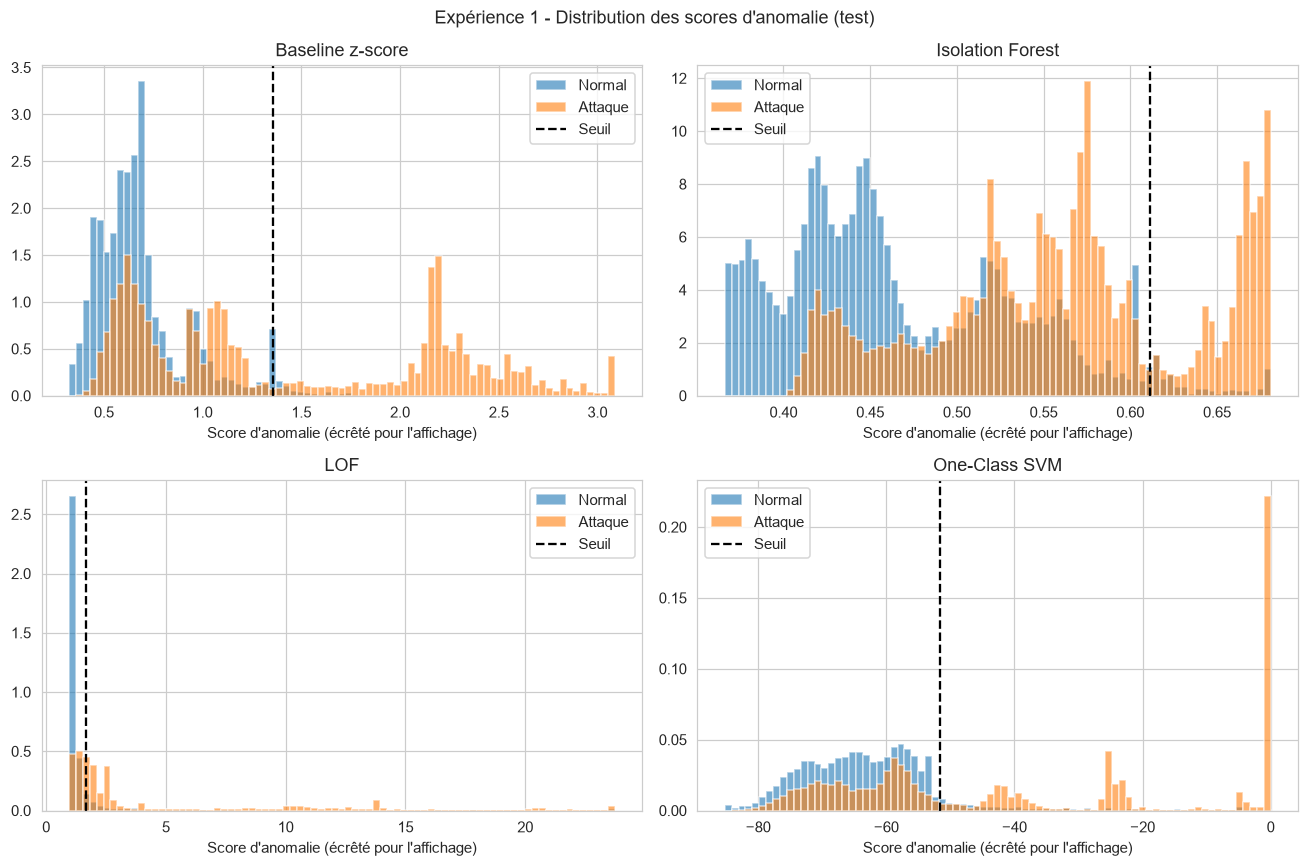

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, name in zip(axes.ravel(), DETECTORS):
    s = test_scores[name]
    lo, hi = np.quantile(s, [0.001, 0.995])
    sc = np.clip(s, lo, hi)
    bins = np.linspace(lo, hi, 80)
    ax.hist(sc[y_test == 0], bins=bins, alpha=0.6, density=True, label="Normal")
    ax.hist(sc[y_test == 1], bins=bins, alpha=0.6, density=True, label="Attaque")
    ax.axvline(np.clip(exp1_thr[name], lo, hi), color="black", ls="--", label="Seuil")
    ax.set_title(name); ax.set_xlabel("Score d'anomalie (écrêté pour l'affichage)")
    ax.legend()
plt.suptitle("Expérience 1 - Distribution des scores d'anomalie (test)")
plt.tight_layout(); save_fig(fig, "exp1_distributions_scores"); plt.show()

## 3.3 Compromis détection / faux positifs (H1)

Seuils fixés sur la validation à 1, 2, 5 et 10 % de FPR, rappel mesuré sur le test.

**Critère H1 (fixé avant les résultats)** : H1 est soutenue si le classement des modèles change selon le budget de FPR, ou si l'écart de rappel entre modèles dépasse 5 points.

Rappel sur le test selon le FPR visé :


FPR visé,0.010000,0.020000,0.050000,0.100000
modèle,,,,
Baseline z-score,42.0%,43.0%,43.1%,60.9%
Isolation Forest,22.7%,24.1%,24.5%,52.2%
LOF,0.0%,28.4%,65.9%,80.3%
One-Class SVM,39.0%,43.0%,52.0%,53.6%


FPR obtenu sur le test :


FPR visé,0.010000,0.020000,0.050000,0.100000
modèle,,,,
Baseline z-score,0.9%,2.2%,3.5%,11.3%
Isolation Forest,1.3%,2.5%,2.8%,12.0%
LOF,0.3%,1.6%,8.6%,15.4%
One-Class SVM,1.9%,3.2%,7.3%,11.6%


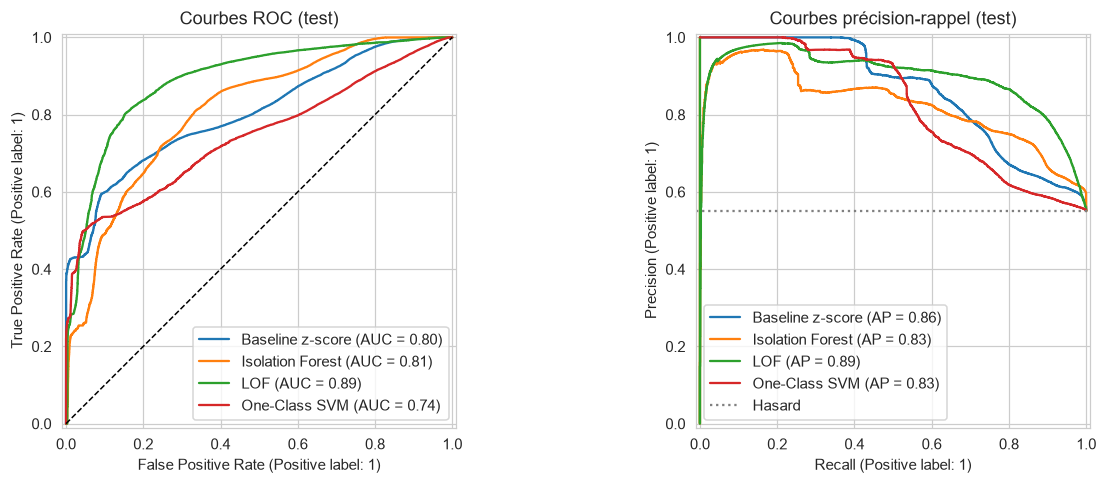

In [17]:
rows = []
for name in DETECTORS:
    for f in FPR_LEVELS:
        thr = threshold_from_normals(val_scores[name][val_normal], f)
        m = detection_metrics(y_test, test_scores[name], thr)
        rows.append({"modèle": name, "FPR visé": f, "Rappel test": m["Rappel"],
                     "FPR test": m["FPR"], "Précision test": m["Précision"]})
tradeoff = pd.DataFrame(rows)
save_table(tradeoff, "exp1_compromis")
recall_at = tradeoff.pivot(index="modèle", columns="FPR visé", values="Rappel test")
fpr_at = tradeoff.pivot(index="modèle", columns="FPR visé", values="FPR test")
print("Rappel sur le test selon le FPR visé :")
display(recall_at.style.format("{:.1%}").background_gradient(cmap="Greens", axis=0))
print("FPR obtenu sur le test :")
display(fpr_at.style.format("{:.1%}"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in DETECTORS:
    RocCurveDisplay.from_predictions(y_test, test_scores[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, test_scores[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].axhline(y_test.mean(), color="grey", ls=":", label="Hasard"); axes[1].legend()
axes[0].set_title("Courbes ROC (test)"); axes[1].set_title("Courbes précision-rappel (test)")
plt.tight_layout(); save_fig(fig, "exp1_roc_pr"); plt.show()

In [18]:
# Verdict H1
ranking = recall_at.rank(axis=0, ascending=False)
classement_change = (ranking.nunique(axis=1) > 1).any()
ecart_rappel = exp1_test["Rappel"].max() - exp1_test["Rappel"].min()

print(f"- Rappel au seuil commun : de {exp1_test['Rappel'].min():.1%} à {exp1_test['Rappel'].max():.1%} "
      f"(écart {ecart_rappel:.1%}) ; FPR test de {exp1_test['FPR'].min():.1%} à {exp1_test['FPR'].max():.1%}")
print(f"- Classement des modèles {'qui CHANGE' if classement_change else 'identique'} selon le budget de FPR")
for f in FPR_LEVELS:
    print(f"  · FPR visé {f:.0%} : meilleur rappel = {recall_at[f].idxmax()} ({recall_at[f].max():.1%})")
print(f"-> H1 {'SOUTENUE' if (classement_change or ecart_rappel > 0.05) else 'NON SOUTENUE'}")

- Rappel au seuil commun : de 24.5% à 65.9% (écart 41.4%) ; FPR test de 2.8% à 8.6%
- Classement des modèles qui CHANGE selon le budget de FPR
  · FPR visé 1% : meilleur rappel = Baseline z-score (42.0%)
  · FPR visé 2% : meilleur rappel = One-Class SVM (43.0%)
  · FPR visé 5% : meilleur rappel = LOF (65.9%)
  · FPR visé 10% : meilleur rappel = LOF (80.3%)
-> H1 SOUTENUE


## 3.4 Détection par famille

Taux de détection de chaque famille sur le test (*Normal* = FPR). Sert à répondre à **Q2** : quelles attaques ressemblent au trafic normal ?

In [19]:
def family_detection(scores, thr, frame=test_df):
    return pd.Series(scores >= thr, index=frame.index).groupby(frame["attack_cat"]).mean()

fam_exp1 = pd.DataFrame({name: family_detection(test_scores[name], exp1_thr[name]) for name in DETECTORS})
fam_exp1["flux (test)"] = test_df["attack_cat"].value_counts()
fam_exp1 = fam_exp1.sort_values(best_name, ascending=False)
save_table(fam_exp1, "exp1_detection_par_famille")
attack_rows = [f for f in fam_exp1.index if f != "Normal"]
(fam_exp1.style.format({c: "{:.1%}" for c in DETECTORS})
 .background_gradient(subset=pd.IndexSlice[attack_rows, DETECTORS], cmap="RdYlGn", vmin=0, vmax=1))

,Baseline z-score,Isolation Forest,LOF,One-Class SVM,flux (test)
attack_cat,,,,,
Generic,57.6%,57.5%,97.3%,93.3%,18871
Backdoor,89.0%,3.1%,73.2%,65.0%,583
Analysis,91.3%,2.1%,68.5%,54.5%,677
Exploits,27.4%,0.4%,56.5%,21.1%,11132
DoS,68.4%,0.7%,55.3%,35.5%,4089
Worms,0.0%,0.0%,25.0%,22.7%,44
Fuzzers,22.2%,2.3%,24.8%,20.6%,6062
Reconnaissance,9.0%,0.1%,14.7%,4.8%,3496
Shellcode,0.0%,0.0%,12.2%,0.8%,378


## 3.5 Faux positifs et faux négatifs (modèle retenu)

Quels flux normaux déclenchent des alertes, et quel est le profil des erreurs ?

Analyse faite sur le test pour comprendre les erreurs : aucun modèle ni seuil n'est modifié.

In [20]:
pred_best = test_scores[best_name] >= exp1_thr[best_name]
is_normal = y_test == 0

for col in ["service", "state"]:
    t = (pd.DataFrame({col: test_df[col].to_numpy(), "alerte": pred_best})[is_normal]
         .groupby(col)["alerte"].agg(flux_normaux="count", taux_FP="mean"))
    t["part des FP"] = t["taux_FP"] * t["flux_normaux"] / max(1, pred_best[is_normal].sum())
    t = t.sort_values("part des FP", ascending=False).head(8)
    save_table(t, f"exp1_fp_par_{col}")
    print(f"Faux positifs de {best_name} par {col} :")
    display(t.style.format({"taux_FP": "{:.1%}", "part des FP": "{:.1%}"}))

outcome = np.select(
    [is_normal & ~pred_best, is_normal & pred_best, ~is_normal & pred_best, ~is_normal & ~pred_best],
    ["Vrai négatif", "Faux positif", "Vrai positif", "Faux négatif"], default="")
PROFILE_VARS = [c for c in ["dur", "sbytes", "dbytes", "spkts", "dpkts", "rate", "sttl", "dttl",
                            "smean", "dmean", "ct_srv_src", "ct_dst_src_ltm"] if c in FEATURES]
profile = test_df[PROFILE_VARS].groupby(outcome).median().T
profile = profile[[c for c in ["Vrai négatif", "Faux positif", "Vrai positif", "Faux négatif"] if c in profile]]
save_table(profile, "exp1_profil_erreurs")
print("Médianes des variables selon le type de décision :")
profile

Faux positifs de LOF par service :


,flux_normaux,taux_FP,part des FP
service,,,
-,27375,8.7%,75.1%
http,4013,10.7%,13.5%
ftp,758,20.7%,4.9%
dns,3068,3.1%,3.0%
smtp,635,7.2%,1.4%
ftp-data,949,3.9%,1.2%
ssh,200,13.0%,0.8%
radius,2,50.0%,0.0%


Faux positifs de LOF par state :


,flux_normaux,taux_FP,part des FP
state,,,
FIN,24172,7.1%,54.2%
INT,4485,15.4%,21.7%
CON,6633,7.5%,15.6%
REQ,1707,15.5%,8.3%
ACC,2,100.0%,0.1%
RST,1,100.0%,0.0%


Médianes des variables selon le type de décision :


,Vrai négatif,Faux positif,Vrai positif,Faux négatif
dur,0.224292,0.104992,0.000009,0.432565
sbytes,978.000000,800.000000,114.000000,664.000000
dbytes,354.000000,354.000000,0.000000,268.000000
spkts,10.000000,10.000000,2.000000,10.000000
dpkts,8.000000,8.000000,0.000000,6.000000
rate,107.477348,234.007846,111111.107200,45.452379
sttl,62.000000,62.000000,254.000000,254.000000
dttl,29.000000,29.000000,0.000000,252.000000
smean,73.000000,73.000000,57.000000,88.000000
dmean,76.000000,57.000000,0.000000,44.000000


# Phase 4 - Expérience 2 : contamination de l'entraînement


**Hypothèse H2** Plus la contamination augmente, moins les détecteurs distinguent le normal des attaques.

- Taille fixe: on remplace des normaux au lieu d'en ajouter, pour que seul le taux d'attaques change.
- Attaques tirées au hasard dans toutes les familles : hypothèse la plus neutre.
- Prétraitement appris sur les données contaminées : en réalité, on ne sait pas qu'elles le sont.
- Seuil fixé sur du trafic propre : on isole l'effet de la contamination sur le modèle
- 3 tirages : à 1 %, seules 200 attaques sont injectées ; le résultat dépend de celles qui sont tirées.

## 4.1 Construction des jeux contaminés

Le tirage 1 utilise la même graine que la phase 3 : à 0 %, il redonne exactement `X_fit`.

In [21]:
def contaminated_fit(level, seed):
    # level : part d'attaques dans les N_FIT flux d'entraînement
    n_att = int(round(level * N_FIT))
    normals = normal_pool.sample(n=N_FIT - n_att, random_state=seed)
    attacks = attack_pool.sample(n=n_att, random_state=seed)
    return pd.concat([normals, attacks])

SEEDS = [RANDOM_STATE + k for k in range(N_SEEDS)]
assert contaminated_fit(0.0, SEEDS[0])[FEATURES].equals(X_fit), "le niveau 0 % doit redonner X_fit"

# Composition des jeux du tirage 1 (familles des attaques injectées)
compo = pd.DataFrame({f"{lvl:.0%}": contaminated_fit(lvl, SEEDS[0])["attack_cat"].value_counts()
                      for lvl in CONTAMINATION_LEVELS}).fillna(0).astype(int)
compo = compo.loc[compo.max(axis=1).sort_values(ascending=False).index]
save_table(compo, "exp2_composition")
compo

,0%,1%,2%,5%,10%
attack_cat,,,,,
Normal,20000,19800,19600,19000,18000
Generic,0,75,143,343,686
Exploits,0,50,108,277,557
Fuzzers,0,26,55,130,297
DoS,0,23,39,115,209
Reconnaissance,0,18,39,96,170
Analysis,0,4,9,19,39
Backdoor,0,1,2,9,23
Shellcode,0,2,4,10,17


## 4.2 Entraînement à chaque niveau


le niveau 0 % du tirage 1 doit redonner exactement les résultats de la phase 3.

In [22]:
exp2_rows, exp2_fam_rows, exp2_scores = [], [], {}
t_start = time.perf_counter()

for seed in SEEDS:
    for lvl in CONTAMINATION_LEVELS:
        X_c = contaminated_fit(lvl, seed)[FEATURES]
        for name, est in make_detectors(seed).items():
            pipe = make_pipeline(est).fit(X_c)
            thr = threshold_from_normals(anomaly_score(pipe, X_val_normal))
            s_test = anomaly_score(pipe, X_test)
            exp2_rows.append({"tirage": seed, "contamination": lvl, "modèle": name,
                              **detection_metrics(y_test, s_test, thr)})
            for fam_name, rate in family_detection(s_test, thr).items():
                exp2_fam_rows.append({"tirage": seed, "contamination": lvl, "modèle": name,
                                      "famille": fam_name, "taux": rate})
            if seed == SEEDS[0] and lvl in (CONTAMINATION_LEVELS[0], CONTAMINATION_LEVELS[-1]):
                exp2_scores[(name, lvl)] = (s_test, thr)
        print(f"tirage {SEEDS.index(seed) + 1}/{N_SEEDS} | contamination {lvl:>4.0%} | "
              f"{time.perf_counter() - t_start:5.0f} s")

exp2 = pd.DataFrame(exp2_rows)
exp2_fam = pd.DataFrame(exp2_fam_rows)
save_table(exp2, "exp2_resultats_bruts")

# Contrôle de cohérence avec la phase 3
ref = exp2[(exp2["tirage"] == SEEDS[0]) & (exp2["contamination"] == 0.0)].set_index("modèle")
for name in DETECTORS:
    for m in ["Rappel", "FPR", "PR-AUC"]:
        assert np.isclose(ref.loc[name, m], exp1_test.loc[name, m]), (name, m)
print("Contrôle réussi : le niveau 0 % (tirage 1) reproduit exactement l'expérience 1.")

tirage 1/3 | contamination   0% |    15 s


tirage 1/3 | contamination   1% |    31 s


tirage 1/3 | contamination   2% |    46 s


tirage 1/3 | contamination   5% |    62 s


tirage 1/3 | contamination  10% |    78 s


...

tirage 3/3 | contamination   0% |   174 s


tirage 3/3 | contamination   1% |   190 s


tirage 3/3 | contamination   2% |   205 s


tirage 3/3 | contamination   5% |   221 s


tirage 3/3 | contamination  10% |   236 s
Contrôle réussi : le niveau 0 % (tirage 1) reproduit exactement l'expérience 1.


Le niveau 0 % du tirage 1 redonne exactement les résultats de la phase 3 : les deux expériences sont cohérentes.

## 4.3 Résultats moyens

Moyenne ± écart-type sur les 3 tirages, pour chaque détecteur et chaque niveau.

In [23]:
METRICS2 = ["Rappel", "FPR", "F1", "PR-AUC"]
exp2_mean = exp2.groupby(["modèle", "contamination"], sort=False)[METRICS2].mean()
exp2_std = exp2.groupby(["modèle", "contamination"], sort=False)[METRICS2].std()
exp2_summary = pd.DataFrame(index=exp2_mean.index)
for m in METRICS2:
    exp2_summary[m] = [f"{a:.1%} ± {b:.1%}" for a, b in zip(exp2_mean[m], exp2_std[m])]
save_table(exp2_mean, "exp2_moyennes"); save_table(exp2_std, "exp2_ecarts_types")
exp2_summary

,,Rappel,FPR,F1,PR-AUC
modèle,contamination,,,,
Baseline z-score,0.00,43.3% ± 0.2%,3.2% ± 0.6%,59.4% ± 0.3%,86.5% ± 0.1%
Isolation Forest,0.00,23.8% ± 0.6%,2.6% ± 0.2%,37.8% ± 0.7%,81.8% ± 1.0%
LOF,0.00,64.0% ± 5.9%,8.6% ± 0.1%,74.7% ± 4.3%,88.9% ± 1.5%
One-Class SVM,0.00,52.1% ± 0.1%,7.7% ± 0.3%,65.8% ± 0.1%,82.7% ± 0.2%
Baseline z-score,0.01,39.6% ± 2.8%,4.0% ± 0.1%,55.4% ± 2.9%,85.6% ± 0.1%
Isolation Forest,0.01,23.3% ± 0.2%,2.5% ± 0.1%,37.2% ± 0.2%,82.3% ± 1.0%
LOF,0.01,42.8% ± 3.7%,8.9% ± 0.3%,57.0% ± 3.6%,76.6% ± 1.4%
One-Class SVM,0.01,36.1% ± 2.2%,7.4% ± 0.2%,50.7% ± 2.3%,76.2% ± 0.6%
Baseline z-score,0.02,29.9% ± 0.1%,3.9% ± 0.1%,44.9% ± 0.1%,84.5% ± 0.0%


## 4.4 Courbes contamination -> rappel, FPR, F1, PR-AUC

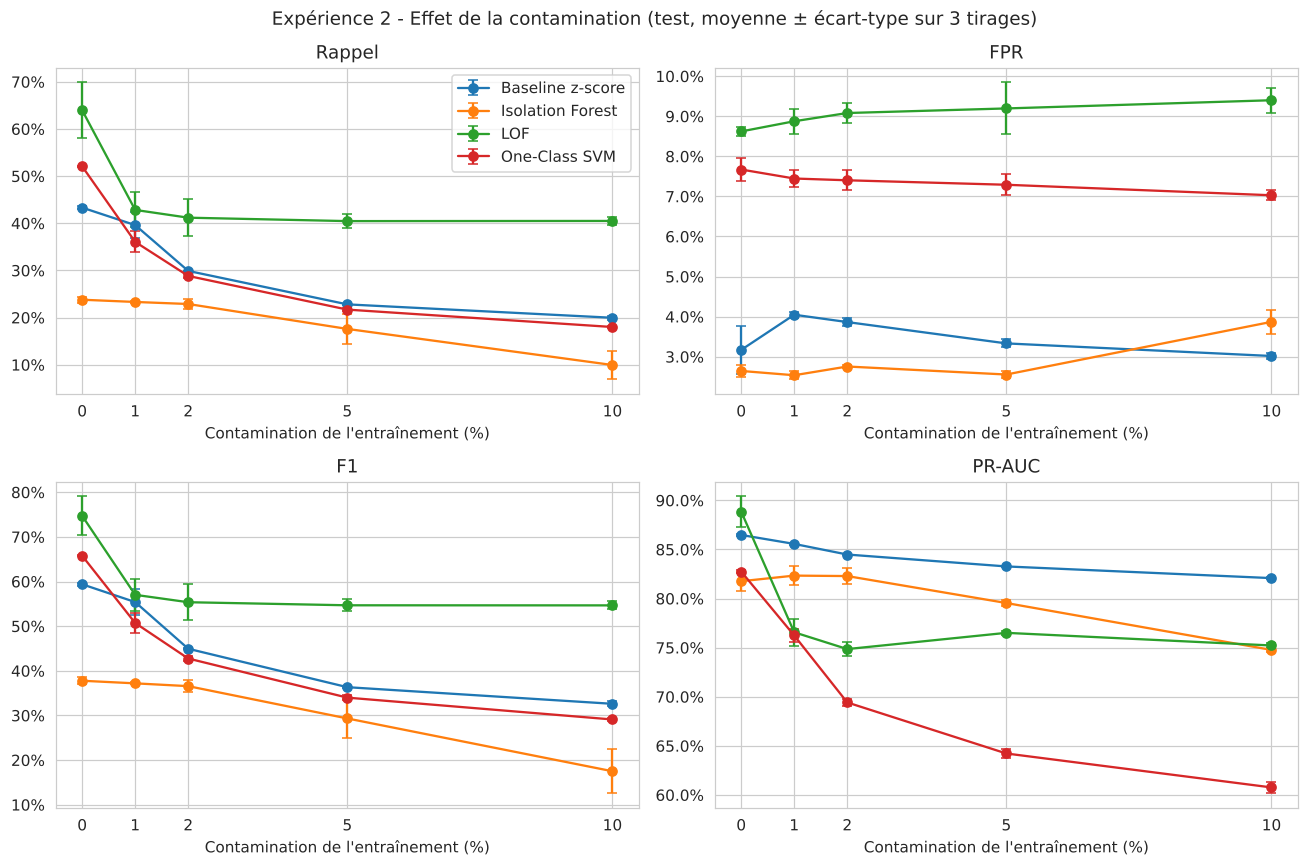

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, m in zip(axes.ravel(), METRICS2):
    for name in DETECTORS:
        mu, sd = exp2_mean.loc[name, m], exp2_std.loc[name, m]
        ax.errorbar(np.array(mu.index) * 100, mu.values, yerr=sd.values, marker="o", capsize=3, label=name)
    ax.set_title(m); ax.set_xlabel("Contamination de l'entraînement (%)")
    ax.set_xticks([lvl * 100 for lvl in CONTAMINATION_LEVELS])
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axes[0, 0].legend()
plt.suptitle("Expérience 2 - Effet de la contamination (test, moyenne ± écart-type sur 3 tirages)")
plt.tight_layout(); save_fig(fig, "exp2_courbes_contamination"); plt.show()

## 4.5 Évolution des distributions de scores

Pour chaque détecteur (tirage 1) : scores du test avec un entraînement propre (0 %) puis contaminé (10 %). Si les attaques se rapprochent du normal à 10 %, le détecteur a « appris » une partie des attaques comme normales.

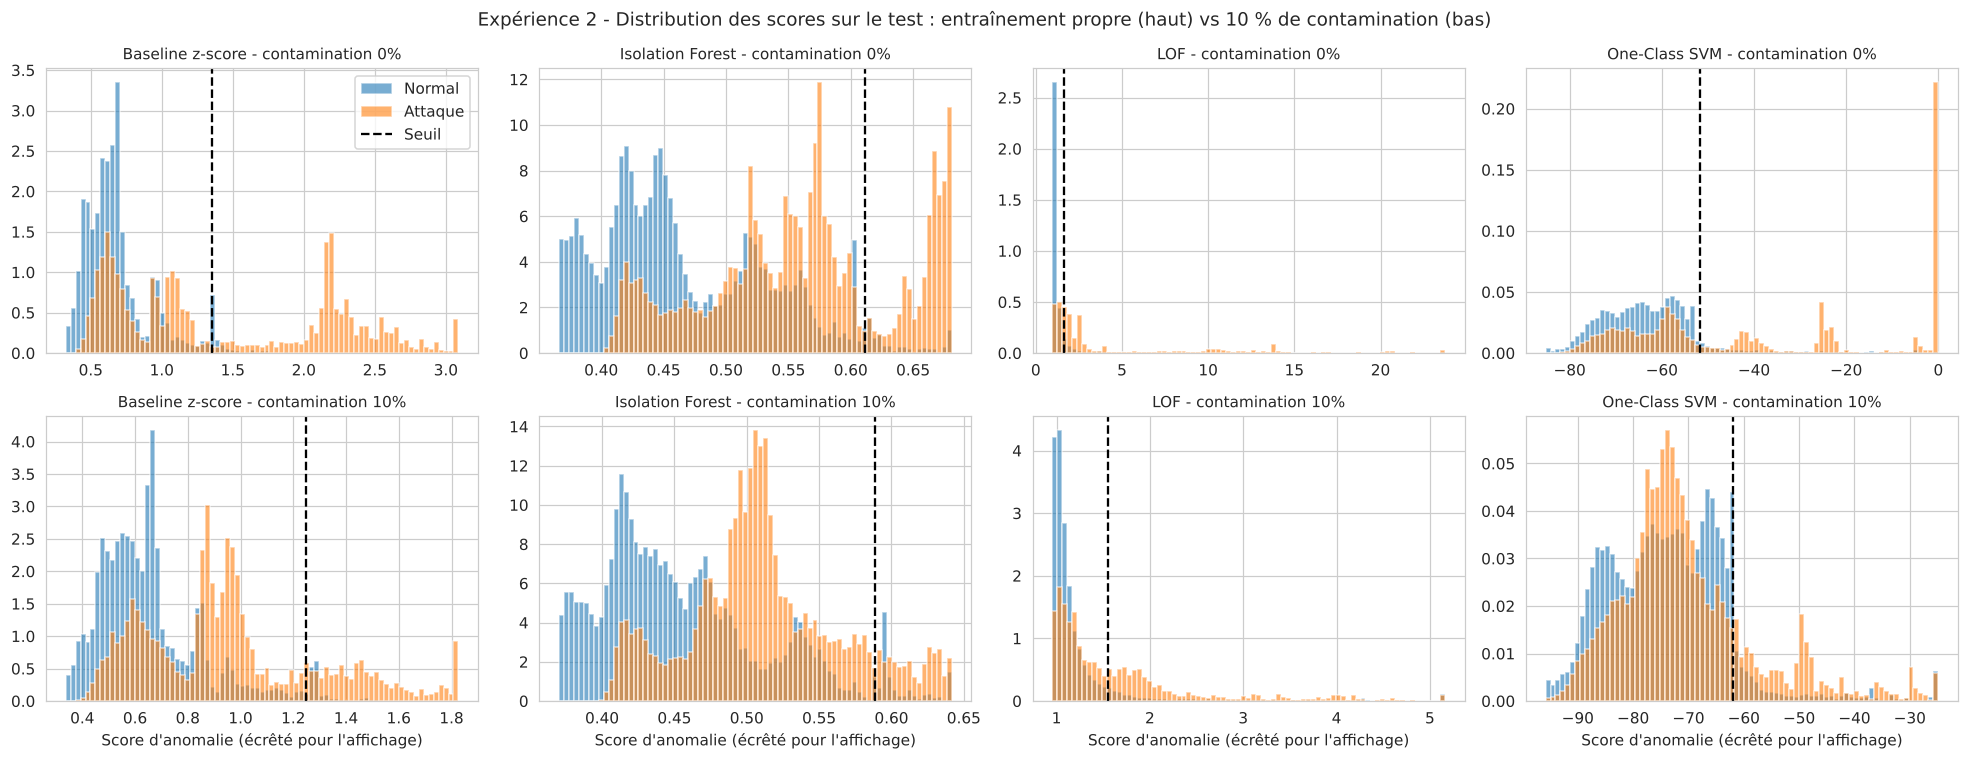

In [25]:
lvl0, lvl1 = CONTAMINATION_LEVELS[0], CONTAMINATION_LEVELS[-1]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, name in enumerate(DETECTORS):
    for i, lvl in enumerate((lvl0, lvl1)):
        ax = axes[i, j]
        s, thr = exp2_scores[(name, lvl)]
        lo, hi = np.quantile(s, [0.001, 0.995])
        sc, bins = np.clip(s, lo, hi), np.linspace(lo, hi, 80)
        ax.hist(sc[y_test == 0], bins=bins, alpha=0.6, density=True, label="Normal")
        ax.hist(sc[y_test == 1], bins=bins, alpha=0.6, density=True, label="Attaque")
        ax.axvline(np.clip(thr, lo, hi), color="black", ls="--", label="Seuil")
        ax.set_title(f"{name} - contamination {lvl:.0%}", fontsize=10)
        if i == 1: ax.set_xlabel("Score d'anomalie (écrêté pour l'affichage)")
axes[0, 0].legend()
plt.suptitle("Expérience 2 - Distribution des scores sur le test : entraînement propre (haut) vs 10 % de contamination (bas)")
plt.tight_layout(); save_fig(fig, "exp2_distributions_scores"); plt.show()

**Résultat**
- Baseline : les attaques ne disparaissent pas, elles se rapprochent du normal. Le groupe lointain (2,0–3,0 à 0 %) est ramené vers 1,2–1,8, et un autre groupe passe sous le seuil. Les attaques injectées gonflent les écarts-types appris, ce qui « écrase » tous les écarts.
- One-Class SVM : le pic d'attaques à 0 (très loin du normal) disparaît. La frontière s'est élargie pour englober les attaques, qui se retrouvent mélangées au trafic normal.
- LOF : les attaques se resserrent contre le pic normal (la plupart sous 2,5 au lieu de 1 à 20) : elles ont désormais des « voisins » dans l'entraînement.
- Isolation Forest : la masse d'attaques se décale vers le trafic normal (0,50 au lieu de 0,55–0,60).

## 4.6 Verdict H2 et seuil critique

- **H2** : critère défini en tête de phase (PR-AUC à 10 % vs 0 %, baisse supérieure à l'écart-type).
- Seuil critique : premier niveau où le rappel moyen perd plus de 5 points par rapport à 0 % (même seuil de pertinence pratique que pour H1).

In [26]:
rows = []
for name in DETECTORS:
    mu, sd = exp2_mean.loc[name], exp2_std.loc[name]
    drop = mu.loc[lvl0, "PR-AUC"] - mu.loc[lvl1, "PR-AUC"]
    noise = max(sd.loc[lvl0, "PR-AUC"], sd.loc[lvl1, "PR-AUC"])
    critical = [lvl for lvl in CONTAMINATION_LEVELS[1:] if mu.loc[lvl0, "Rappel"] - mu.loc[lvl, "Rappel"] > 0.05]
    rows.append({"modèle": name,
                 "PR-AUC 0 %": mu.loc[lvl0, "PR-AUC"], "PR-AUC 10 %": mu.loc[lvl1, "PR-AUC"],
                 "Baisse PR-AUC": drop, "Écart-type max": noise,
                 "Rappel 0 %": mu.loc[lvl0, "Rappel"], "Rappel 10 %": mu.loc[lvl1, "Rappel"],
                 "FPR 0 %": mu.loc[lvl0, "FPR"], "FPR 10 %": mu.loc[lvl1, "FPR"],
                 "H2 soutenue": bool(drop > 0 and drop > noise),
                 "Seuil critique (rappel −5 pts)": f"{critical[0]:.0%}" if critical else "aucun"})
h2 = pd.DataFrame(rows).set_index("modèle")
save_table(h2, "exp2_verdict_h2")
display(h2.style.format({c: "{:.1%}" for c in h2.columns if "%" in c or c in ("Baisse PR-AUC", "Écart-type max")}))

n_ok = int(h2["H2 soutenue"].sum())
print(f"-> H2 {'SOUTENUE' if n_ok > len(h2) / 2 else 'NON SOUTENUE'} globalement : {n_ok}/{len(h2)} détecteurs")

,PR-AUC 0 %,PR-AUC 10 %,Baisse PR-AUC,Écart-type max,Rappel 0 %,Rappel 10 %,FPR 0 %,FPR 10 %,H2 soutenue,Seuil critique (rappel −5 pts)
modèle,,,,,,,,,,
Baseline z-score,86.5%,82.1%,4.4%,0.1%,43.3%,20.0%,3.2%,3.0%,True,2%
Isolation Forest,81.8%,74.8%,7.0%,1.0%,23.8%,9.9%,2.6%,3.9%,True,5%
LOF,88.9%,75.2%,13.6%,1.5%,64.0%,40.5%,8.6%,9.4%,True,1%
One-Class SVM,82.7%,60.8%,22.0%,0.6%,52.1%,18.0%,7.7%,7.0%,True,1%


-> H2 SOUTENUE globalement : 4/4 détecteurs


## 4.7 Détection par famille : 0 % vs 10 %

Taux de détection moyen (3 tirages) de chaque famille avec un entraînement propre puis contaminé à 10 %. Montre quelles attaques le détecteur cesse de voir quand des attaques se glissent dans l'entraînement.

In [27]:
fam_mean = exp2_fam.groupby(["modèle", "contamination", "famille"])["taux"].mean().unstack("contamination")
fam_delta = pd.DataFrame({name: fam_mean.loc[name][lvl1] - fam_mean.loc[name][lvl0] for name in DETECTORS})
fam_0 = pd.DataFrame({name: fam_mean.loc[name][lvl0] for name in DETECTORS})
fam_10 = pd.DataFrame({name: fam_mean.loc[name][lvl1] for name in DETECTORS})
order = fam_exp1.index
fam_cmp = pd.concat({"0 %": fam_0.loc[order], "10 %": fam_10.loc[order], "Écart": fam_delta.loc[order]}, axis=1)
fam_cmp["flux (test)"] = test_df["attack_cat"].value_counts()
save_table(fam_cmp, "exp2_detection_par_famille")
attack_rows = [f for f in order if f != "Normal"]
(fam_cmp.style.format("{:.1%}", subset=[c for c in fam_cmp.columns if c[0] != "flux (test)"])
 .background_gradient(subset=pd.IndexSlice[attack_rows, [("Écart", d) for d in DETECTORS]],
                      cmap="RdYlGn", vmin=-0.5, vmax=0.5))

**Résultat**
- Les familles les plus injectées sont celles qui disparaissent** : *Generic* (−31 à −58 points selon le détecteur), *Exploits*, *DoS*. Le détecteur a appris ces attaques comme « normales ».
- Les familles presque absentes de l'injection ne bougent pas : *Shellcode* (17 flux injectés) et *Worms* (2 flux) gardent leur taux de détection.
- La baseline ne détecte plus que Generic (46,9 %) : *Backdoor* passe de 89,5 % à 0,9 %, *Analysis* de 91,3 % à 0 %.
- LOF garde la meilleure couverture** : 53 % sur *Backdoor* et *Analysis*, 62 % sur *Generic*.